# Video 1: Introducing the dataset

Notes for this notebook.

This notebook generates the visuals used in the first video of the series. The goal of this video is to explain what H&E, COMET, and Xenium are, and to introduce the four tissue cores in the dataset. There is no deep code walkthrough in the video itself, but the images shown on slides are generated here so they are real data, not illustrations.

All output images are saved into the `outputs` folder next to this notebook. That folder is also where the slide deck images will be placed.


In [1]:
import os
from pathlib import Path

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Output folder ready at:", OUTPUT_DIR.resolve())


Output folder ready at: C:\Users\m6sbhatt\Documents\Personal\python_projects\unumlocalia\outputs


## Load the dataset

We load all four cores. Transcripts are included here since we need them for the Xenium explanation slide later in this notebook. This load step can take under a minute.


In [2]:
from pathlib import Path
from unumlocalia.io import DatasetLoader
import time

DATA_DIR = Path("data/UnumLocalia")

t0 = time.time()
loader = DatasetLoader(str(DATA_DIR)).load(
    do_load_transcripts=True,
    load_boundaries=True,
    load_he=True,
    load_comet=True,
)
print("Load time in seconds:", round(time.time() - t0, 1))
print("Cores found:", list(loader.manifest.cores.keys()))


Load time in seconds: 21.5
Cores found: ['core01_hcc', 'core02_non_tumour', 'core03_tonsil', 'core04_hca']


## Slide: H&E, tissue morphology

This is the modality most viewers already recognize. A plain crop of the core is enough to anchor the explanation.


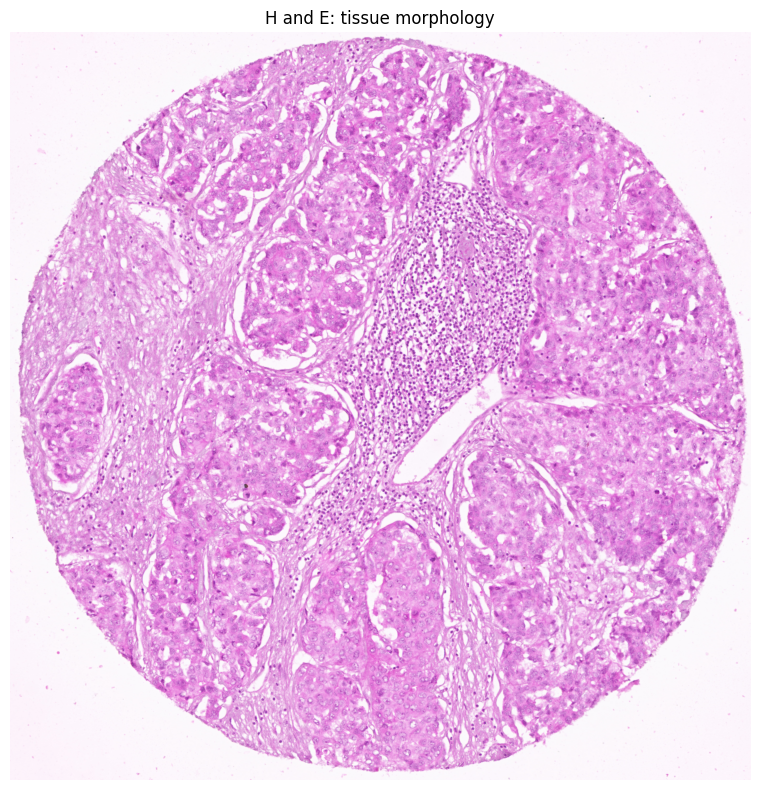

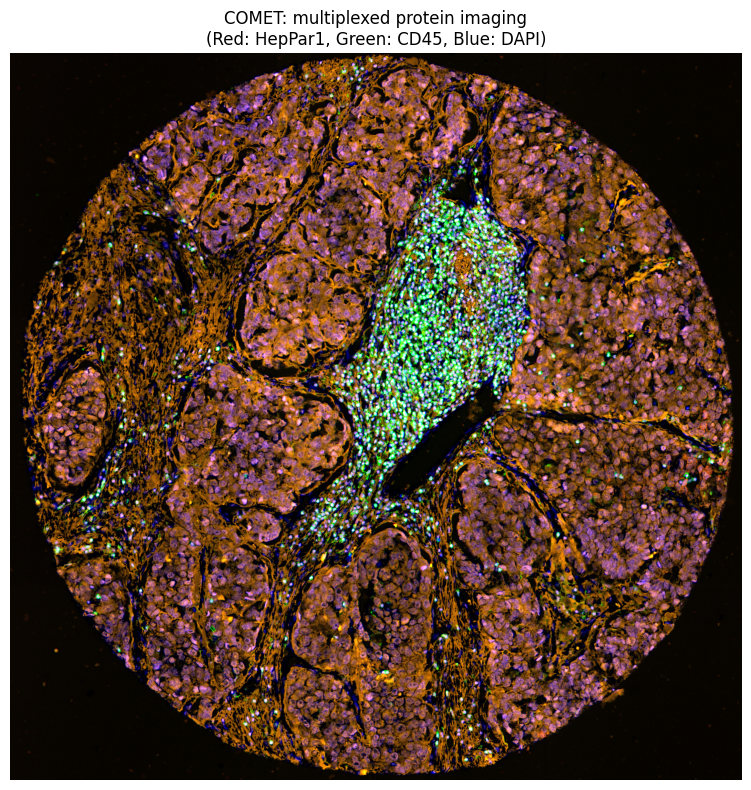

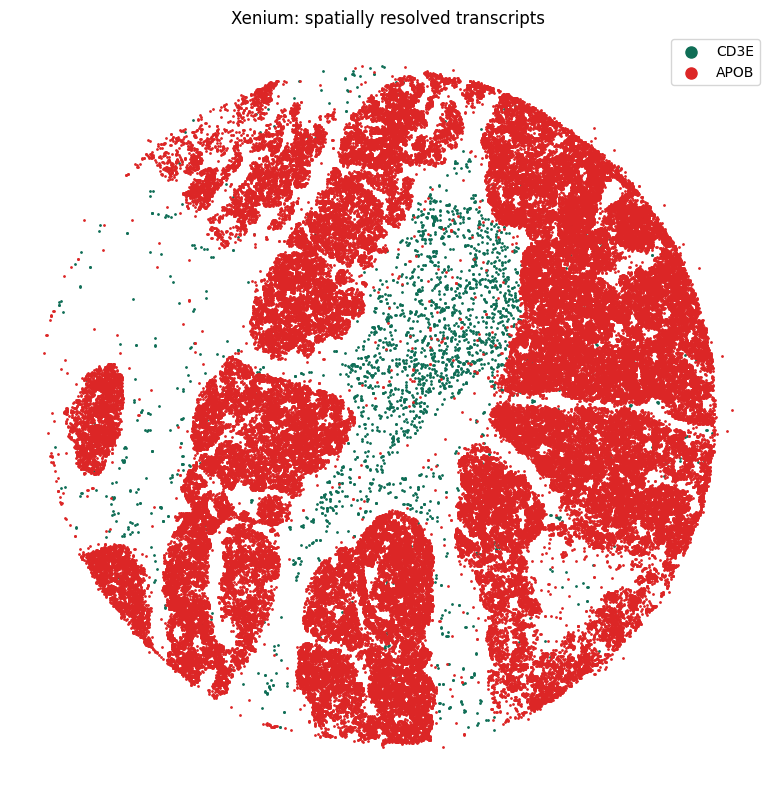

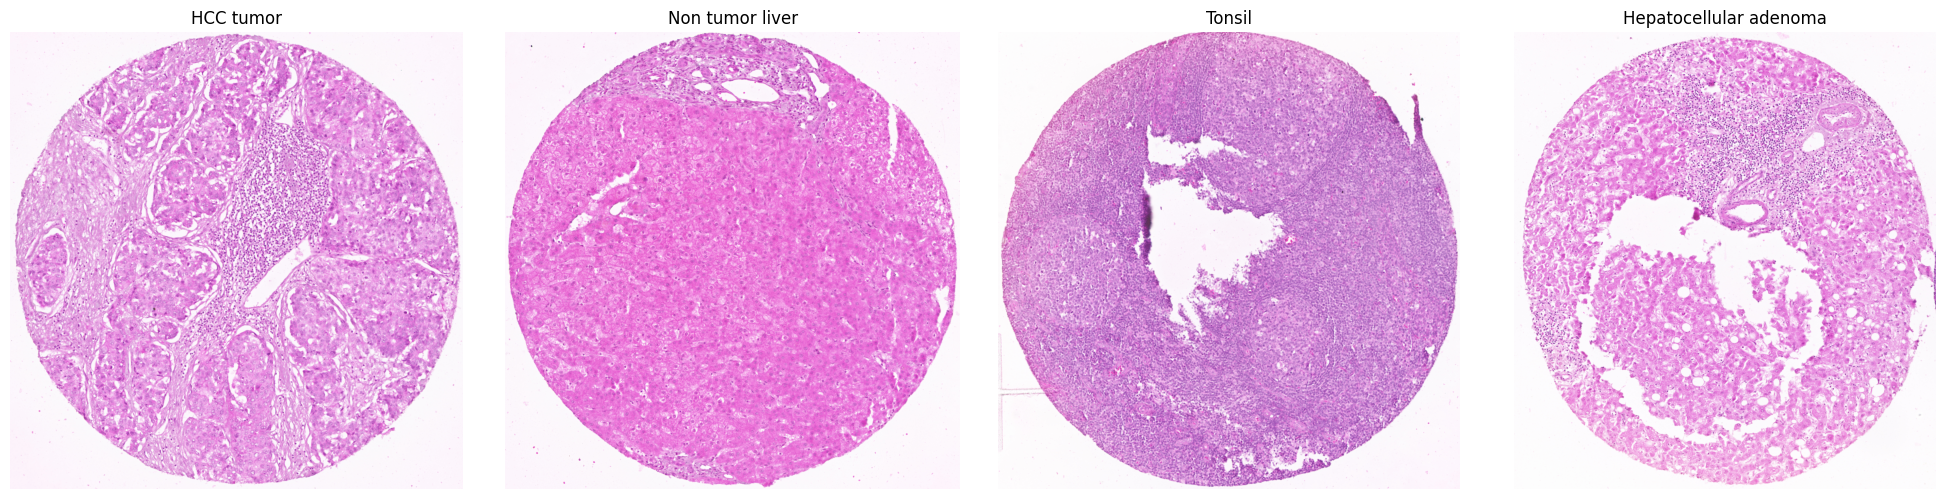

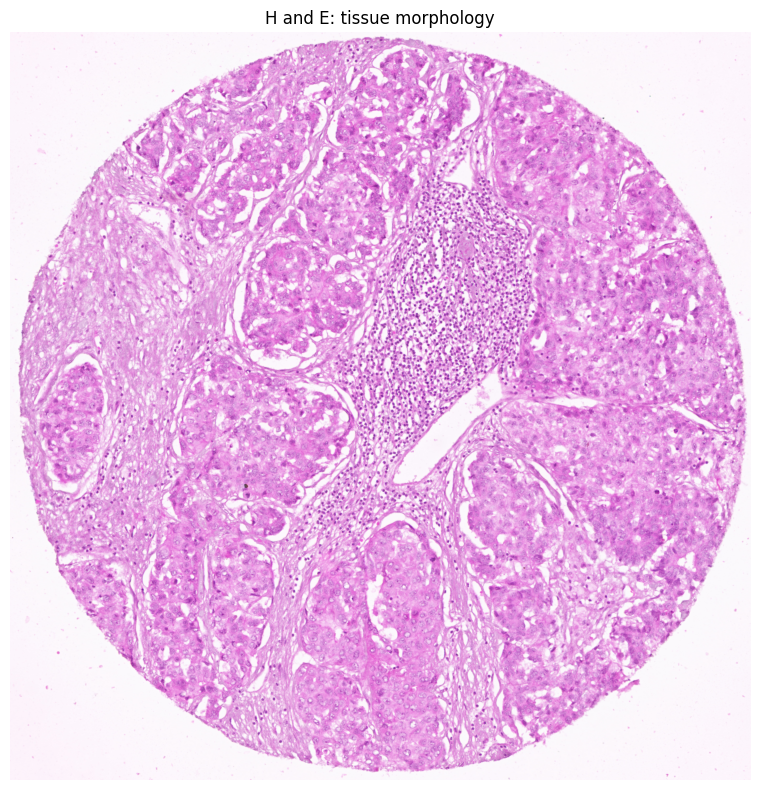

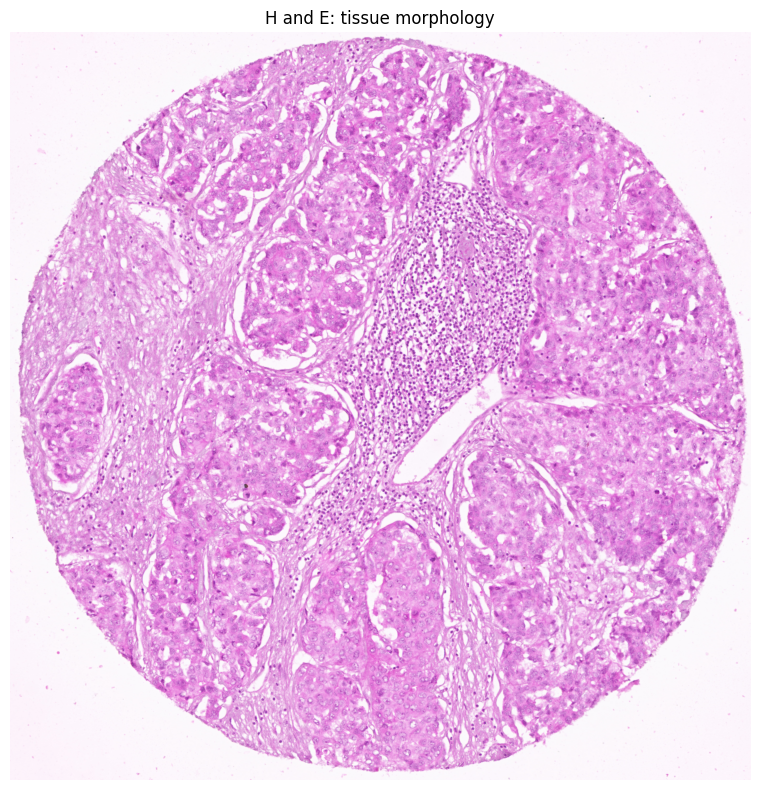

Saved slide_he_explain.png


In [9]:
import matplotlib.pyplot as plt
%matplotlib inline
core_id = "core01_hcc"
he = loader.he_arrays[core_id]

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(he)
ax.set_title("H and E: tissue morphology")
ax.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "slide_he_explain.png", dpi=200, facecolor="white")
plt.show()

print("Saved slide_he_explain.png")


## Slide: COMET, multiplexed protein imaging

COMET measures many protein markers on the same tissue section. To make that concept visible in a single image, we combine three markers into an RGB composite: HepPar1 for hepatocytes, CD45 for immune cells, and DAPI for nuclei.


In [4]:
import numpy as np

def normalize(img):
    img = img.astype(float)
    p1, p99 = np.percentile(img, (1, 99))
    return np.clip((img - p1) / (p99 - p1 + 1e-6), 0, 1)

markers = loader.comet_markers[core_id]
dapi = normalize(loader.get_comet_channel(core_id, markers.index("DAPI")))
cd45 = normalize(loader.get_comet_channel(core_id, markers.index("CD45 - TRITC")))
heppar1 = normalize(loader.get_comet_channel(core_id, markers.index("HepPar1 - TRITC")))

rgb = np.stack([heppar1, cd45, dapi], axis=-1)

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(rgb)
ax.set_title("COMET: multiplexed protein imaging\n(Red: HepPar1, Green: CD45, Blue: DAPI)")
ax.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "slide_comet_explain.png", dpi=200, facecolor="white")
plt.show()

print("Saved slide_comet_explain.png")


Saved slide_comet_explain.png


C:\Users\m6sbhatt\AppData\Local\Temp\ipykernel_14820\3775177712.py:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## Check the transcript table structure

Before building the Xenium explanation slide, we need to confirm the exact column names in the transcript table. Run this cell and check the printed columns before moving to the next cell.


In [5]:
transcripts = loader.transcripts_df[core_id]
print(transcripts.columns.tolist())
print(transcripts.head())
print("Total transcript rows:", len(transcripts))


['transcript_id', 'cell_id', 'overlaps_nucleus', 'feature_name', 'x_location', 'y_location', 'z_location', 'qv', 'fov_name', 'nucleus_distance', 'codeword_index', 'codeword_category', 'is_gene']
     transcript_id     cell_id  overlaps_nucleus feature_name   x_location  \
0  282325380237372  UNASSIGNED                 0        HIF1A  1745.875000   
1  282325380270000  UNASSIGNED                 0         IDUA  1742.046875   
2  282325380256631  kacjccpe-1                 0         AAMP  1744.656250   
3  282402689696824  kacpjofh-1                 1         AAMP  1741.109375   
4  282402689668340  kacikena-1                 0       AARSD1  1732.000000   

    y_location  z_location     qv fov_name  nucleus_distance  codeword_index  \
0  4246.953125   14.531250  40.00       U3         25.937500            4125   
1  4239.250000   14.421875  15.25       U3         32.937500           14643   
2  4320.562500   15.171875  31.25       U3          1.796875            3277   
3  4490.593750  

## Slide: Xenium, spatially resolved transcripts

This plots individual transcript detections as points, colored by gene identity, for two marker genes. This is meant to visually contrast with the pixel based COMET and H and E images, since Xenium data is a set of discrete point detections rather than a continuous image.

Gene panels vary between Xenium designs, so a gene present in one core is not guaranteed to be in the panel used for another. Instead of hardcoding fixed gene names, we search a short candidate list for immune and hepatocyte marker genes, then plot whichever candidate has the highest transcript count in each category. This keeps the cell reusable across all four cores in the later videos.


In [6]:
candidate_immune_genes = ["PTPRC", "CD52", "CD3E", "CD3D", "CD7", "LYZ", "CD14", "ITGAM", "CD68"]
candidate_hepatocyte_genes = ["ALB", "TTR", "APOA1", "SERPINA1", "HNF4A", "ASGR1", "APOB"]

real_genes = transcripts[transcripts["is_gene"] == True]
gene_counts = real_genes["feature_name"].value_counts()

def top_available(candidates, counts):
    present = [g for g in candidates if g in counts.index]
    if not present:
        return None
    return max(present, key=lambda g: counts[g])

immune_gene = top_available(candidate_immune_genes, gene_counts)
hepatocyte_gene = top_available(candidate_hepatocyte_genes, gene_counts)

print("Immune gene selected:", immune_gene)
print("Hepatocyte gene selected:", hepatocyte_gene)

genes_to_show = [g for g in [immune_gene, hepatocyte_gene] if g is not None]
colors = {immune_gene: "#0F6E56", hepatocyte_gene: "#DC2626"}

fig, ax = plt.subplots(figsize=(8, 8))

for gene in genes_to_show:
    sub = real_genes[real_genes["feature_name"] == gene]
    ax.scatter(sub["x_location"], sub["y_location"], s=1, label=gene, color=colors.get(gene))

ax.invert_yaxis()
ax.set_aspect("equal")
ax.legend(markerscale=8)
ax.set_title("Xenium: spatially resolved transcripts")
ax.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "slide_xenium_explain.png", dpi=200, facecolor="white")
plt.show()

print("Saved slide_xenium_explain.png")


Immune gene selected: CD3E
Hepatocyte gene selected: APOB
Saved slide_xenium_explain.png


C:\Users\m6sbhatt\AppData\Local\Temp\ipykernel_14820\1377958886.py:35: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## Slide: dataset overview, all four cores

This gives viewers a single image showing all four tissue types in the dataset side by side.


In [7]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
core_ids = ["core01_hcc", "core02_non_tumour", "core03_tonsil", "core04_hca"]
titles = ["HCC tumor", "Non tumor liver", "Tonsil", "Hepatocellular adenoma"]

for ax, cid, title in zip(axes, core_ids, titles):
    ax.imshow(loader.he_arrays[cid])
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "slide_dataset_overview.png", dpi=200, facecolor="white")
plt.show()

print("Saved slide_dataset_overview.png")


Saved slide_dataset_overview.png


C:\Users\m6sbhatt\AppData\Local\Temp\ipykernel_14820\1300536090.py:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## Napari screenshots, notes only

Napari is used only for viewing here, not run inside this notebook, since it opens a blocking interactive window. Use a separate plain script for this.

Two ways to capture a screenshot.

First, inside the open napari window, use the camera icon in the toolbar, or the menu File then Save Screenshot. This captures whatever is currently visible, at whatever zoom and layer arrangement you have set up.

Second, programmatically, once the viewer window is open and arranged the way you want, run this line in the same script:

viewer.screenshot(path="outputs/napari_overlay_screenshot.png", canvas_only=True)

The canvas_only option leaves out napari's own interface elements, so the saved image is just the layers themselves, suitable for a slide.
